# Stage 2: Core Segmentation Training (Dual MobileNetV3 + LTCA + Alpha Gate + Topological Loss)
### Component C2: Software Emulated Linear Transposed Cross Attention Framework for Noise Resilient Pavement Segmentation

**Project Title:** AI Framework for Sri Lankan Road Management (RoadLens)  
**Research Group:** J26-DS-309  
**Researcher:** Methma C A N (IT23245860) – B.Sc. (Hons) in Information Technology Specializing in Data Science, SLIIT  
**Supervisors:** Ms. Thamali Dassanayake & Ms. Hansi De Silva  

---
### Stage 2 Technical Innovations & Methodology (Proposal Section 2.2 & 3.1)
1. **Software Thermal Sensor:** Standard RGB optical crops ($256 \times 256$) are passed through the frozen Stage 1 `cgan_frozen_sensor.pth` to synthesize pseudo-thermal moisture maps in pure software (bypassing $20,000 physical thermal cameras).
2. **Dual-Stream MobileNetV3 Backbones:** Parallel encoders extract fine spatial micro-crack edges (Visual stream) and shadow-free moisture void features (Pseudo-Thermal stream).
3. **Linear Transposed Cross-Attention (LTCA):** Computes cross-covariance across feature channels ($C \times C$) instead of quadratic spatial pixels ($N \times N$), slashing cross-attention memory overhead from 17 GB to **~67 MB** with $O(N)$ linear complexity.
4. **Scale-Aware Dynamic Alpha Gating:** Dynamically balances deep contextual noise rejection ($\alpha \to 1.0$: rejects broad canopy shadows and glare) against shallow spatial micro-crack detail preservation ($\alpha \to 0.0$: preserves fine hairline cracks $<3\text{ mm}$).
5. **Skeletal Topological Loss ($\mathcal{L}_{Topology}$):** Differentiable morphological pooling penalizes line breaks and enforces continuous unbroken 1-pixel centerlines.
6. **4-Part Precision Output Suite:** Delivers 2D Binary Mask (Output A), 1-Pixel Skeleton (Output B), Soft Confidence Map (Output C), and Red Visual Overlay (Output D) to feed downstream Severity (C3) and GIS (C4).

## 1. Hardware Verification & GPU Configuration
Confirms active NVIDIA T4 GPU accelerator, enables CuDNN benchmark mode, and verifies PyTorch CUDA runtime.

In [12]:
!nvidia-smi

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name:     {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM:      {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    torch.backends.cudnn.benchmark = True
    print("cuDNN Benchmark enabled.")
else:
    print("WARNING: CUDA not detected! Enable GPU in Colab: Runtime > Change runtime type > T4 GPU.")

Tue Oct 20 10:54:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             51W /  400W |     932MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Dependencies Installation
Installs packages for computer vision, morphological operations, and evaluation.

In [13]:
!pip install -q scikit-image albumentations opencv-python matplotlib tqdm torchvision

## 3. Google Drive Mount & High-Speed Local SSD Staging
Mounts Google Drive and stages the `Core_Segmentation` dataset (`train`, `val`, `test`) onto the Colab local NVMe SSD (`/content/local_core_dataset`) for ultra-fast batch loading.

In [14]:
import os
import shutil
from pathlib import Path

try:
    from google.colab import drive
    drive_mount_point = "/content/drive"
    if not os.path.exists(drive_mount_point):
        drive.mount(drive_mount_point)
        print("Google Drive mounted.")
    else:
        print(f"Google Drive already mounted at {drive_mount_point}.")
    DRIVE_ROOT = Path("/content/drive/MyDrive/C2_Pavement_Research")
except ImportError:
    print("Running in local environment.")
    DRIVE_ROOT = Path("./C2_Pavement_Research")

# Paths to Stage 1 Checkpoint and Stage 2 Dataset
WEIGHTS_DIR = DRIVE_ROOT / "weights"
CGAN_WEIGHTS = WEIGHTS_DIR / "cgan_frozen_sensor.pth"
if not CGAN_WEIGHTS.exists():
    CGAN_WEIGHTS = WEIGHTS_DIR / "cgan_generator_best.pth"

CORE_SEG_DRIVE = DRIVE_ROOT / "datasets" / "Core_Segmentation"
EXP_DIR = DRIVE_ROOT / "experiments" / "core_segmentation"
SUITE_DEMOS_DIR = EXP_DIR / "suite_demos"

for d in [WEIGHTS_DIR, EXP_DIR, SUITE_DEMOS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Local fast NVMe SSD directory
LOCAL_DATASET = Path("/content/local_core_dataset")
if not LOCAL_DATASET.exists() and CORE_SEG_DRIVE.exists():
    print("Staging Core_Segmentation to local high-speed SSD...")
    shutil.copytree(str(CORE_SEG_DRIVE), str(LOCAL_DATASET))
    print("Local SSD staging complete!")

DATASET_ROOT = LOCAL_DATASET if LOCAL_DATASET.exists() else CORE_SEG_DRIVE
TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "val"
TEST_DIR = DATASET_ROOT / "test"

print(f"Trained cGAN Sensor Weights: {CGAN_WEIGHTS} (Exists: {CGAN_WEIGHTS.exists()})")
print(f"Core Segmentation Train Dir: {TRAIN_DIR} (Exists: {TRAIN_DIR.exists()})")
print(f"Core Segmentation Val Dir:   {VAL_DIR} (Exists: {VAL_DIR.exists()})")
print(f"Core Segmentation Test Dir:  {TEST_DIR} (Exists: {TEST_DIR.exists()})")

Google Drive already mounted at /content/drive.
Trained cGAN Sensor Weights: /content/drive/MyDrive/C2_Pavement_Research/weights/cgan_frozen_sensor.pth (Exists: True)
Core Segmentation Train Dir: /content/local_core_dataset/train (Exists: True)
Core Segmentation Val Dir:   /content/local_core_dataset/val (Exists: True)
Core Segmentation Test Dir:  /content/local_core_dataset/test (Exists: True)


## 4. Loading & Verifying the Frozen cGAN Software Sensor
Loads the Stage 1 trained Pix2Pix generator and freezes all parameters (`requires_grad = False`). This acts as our pure-software thermal sensor.

In [15]:
import torch.nn as nn

# UNet-256 Generator Architecture for Software Thermal Emulation
class UNetDownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, normalize: bool = True):
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=not normalize)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.block = nn.Sequential(*layers)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

class UNetUpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, dropout: float = 0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(out_channels),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0.0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)
    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.block(x)
        return torch.cat([x, skip], dim=1)

class UNetGenerator256(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 1):
        super().__init__()
        self.down1 = UNetDownBlock(in_channels, 64, normalize=False)
        self.down2 = UNetDownBlock(64, 128)
        self.down3 = UNetDownBlock(128, 256)
        self.down4 = UNetDownBlock(256, 512)
        self.down5 = UNetDownBlock(512, 512)
        self.down6 = UNetDownBlock(512, 512)
        self.down7 = UNetDownBlock(512, 512)
        self.down8 = UNetDownBlock(512, 512, normalize=False)
        self.up1 = UNetUpBlock(512, 512, dropout=0.5)
        self.up2 = UNetUpBlock(1024, 512, dropout=0.5)
        self.up3 = UNetUpBlock(1024, 512, dropout=0.5)
        self.up4 = UNetUpBlock(1024, 512)
        self.up5 = UNetUpBlock(1024, 256)
        self.up6 = UNetUpBlock(512, 128)
        self.up7 = UNetUpBlock(256, 64)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        d1 = self.down1(x); d2 = self.down2(d1); d3 = self.down3(d2); d4 = self.down4(d3)
        d5 = self.down5(d4); d6 = self.down6(d5); d7 = self.down7(d6); d8 = self.down8(d7)
        u1 = self.up1(d8, d7); u2 = self.up2(u1, d6); u3 = self.up3(u2, d5); u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3); u6 = self.up6(u5, d2); u7 = self.up7(u6, d1)
        return self.final(u7)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cgan_sensor = UNetGenerator256(in_channels=3, out_channels=1).to(device)

if CGAN_WEIGHTS.exists():
    state = torch.load(CGAN_WEIGHTS, map_location=device)
    if "generator_state_dict" in state:
        state = state["generator_state_dict"]
    cgan_sensor.load_state_dict(state)
    print(f"Successfully loaded trained cGAN weights from {CGAN_WEIGHTS}")
else:
    print("Warning: cGAN weights file not found. Using initialized weights for architecture testing.")

# Freeze all software sensor weights
for p in cgan_sensor.parameters():
    p.requires_grad = False
cgan_sensor.eval()
print("cGAN Software Sensor is FROZEN (requires_grad = False). Ready for Stage 2.")

Successfully loaded trained cGAN weights from /content/drive/MyDrive/C2_Pavement_Research/weights/cgan_frozen_sensor.pth
cGAN Software Sensor is FROZEN (requires_grad = False). Ready for Stage 2.


## 5. Core Segmentation Dataset & Ground-Truth Skeletonization
Discovers paired pavement images and ground-truth masks across `train`, `val`, and `test` splits. Automatically extracts ground-truth continuous 1-pixel centerlines via morphological thinning for topological supervision.

In [20]:
import cv2
import numpy as np
import random
from pathlib import Path
import torch
from typing import List, Tuple
from torch.utils.data import Dataset, DataLoader

def discover_segmentation_pairs(split_dir: Path) -> List[Tuple[Path, Path]]:
    split_dir = Path(split_dir)
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    img_dir, mask_dir = None, None

    # Detect subdirectories dynamically (matches 'train_images', 'images', 'train_masks', etc.)
    for sub in split_dir.iterdir():
        if sub.is_dir():
            name = sub.name.lower()
            if any(k in name for k in ["image", "img", "rgb"]) and img_dir is None:
                img_dir = sub
            elif any(k in name for k in ["mask", "label", "gt", "seg"]) and mask_dir is None:
                mask_dir = sub

    if img_dir and mask_dir:
        imgs = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in valid_exts}
        msks = {p.stem: p for p in mask_dir.iterdir() if p.suffix.lower() in valid_exts}
        common = sorted(list(set(imgs.keys()).intersection(set(msks.keys()))))
        if len(common) > 0:
            return [(imgs[k], msks[k]) for k in common]

    # Fallback recursive matching if subfolders weren't matched
    all_imgs = sorted([p for p in split_dir.rglob("*") if p.suffix.lower() in valid_exts and any(k in p.parent.name.lower() for k in ["image", "img", "rgb"])])
    all_msks = sorted([p for p in split_dir.rglob("*") if p.suffix.lower() in valid_exts and any(k in p.parent.name.lower() for k in ["mask", "label", "gt", "seg"])])

    img_dict = {p.stem: p for p in all_imgs}
    msk_dict = {p.stem: p for p in all_msks}
    common = sorted(list(set(img_dict.keys()).intersection(set(msk_dict.keys()))))
    return [(img_dict[k], msk_dict[k]) for k in common]

def morphological_thinning(mask: np.ndarray) -> np.ndarray:
    """Extracts continuous 1-pixel skeleton centerline."""
    binary = ((mask > 127) * 255).astype(np.uint8)
    try:
        skeleton = cv2.ximgproc.thinning(binary, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)
    except (AttributeError, cv2.error):
        kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
        skeleton = np.zeros_like(binary)
        temp = binary.copy()
        while True:
            eroded = cv2.erode(temp, kernel)
            opened = cv2.morphologyEx(eroded, cv2.MORPH_OPEN, kernel)
            subset = cv2.subtract(eroded, opened)
            skeleton = cv2.bitwise_or(skeleton, subset)
            temp = eroded.copy()
            if cv2.countNonZero(temp) == 0:
                break
    return (skeleton > 0).astype(np.float32)

class CoreSegmentationDataset(Dataset):
    def __init__(self, split_dir: Path, img_size: int = 256, is_train: bool = True):
        self.split_dir = Path(split_dir)
        self.img_size = img_size
        self.is_train = is_train
        self.pairs = discover_segmentation_pairs(self.split_dir)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        img_path, mask_path = self.pairs[idx]

        rgb = cv2.imread(str(img_path))
        if rgb is None:
            raise ValueError(f"Failed to load image: {img_path}")
        rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            mask = cv2.imread(str(mask_path))
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

        rgb = cv2.resize(rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)

        if self.is_train:
            if random.random() > 0.5:
                rgb = np.fliplr(rgb); mask = np.fliplr(mask)
            if random.random() > 0.5:
                rgb = np.flipud(rgb); mask = np.flipud(mask)
            if random.random() > 0.5:
                k = random.choice([1, 2, 3])
                rgb = np.rot90(rgb, k); mask = np.rot90(mask, k)

        skel = morphological_thinning(mask)

        # RGB in [-1, 1], Mask and Skeleton in {0.0, 1.0}
        rgb_t = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().div_(127.5).sub_(1.0)
        mask_t = torch.from_numpy((mask > 127).astype(np.float32)).unsqueeze(0)
        skel_t = torch.from_numpy(skel).unsqueeze(0)

        return rgb_t, mask_t, skel_t

train_dataset = CoreSegmentationDataset(TRAIN_DIR, img_size=256, is_train=True)
val_dataset = CoreSegmentationDataset(VAL_DIR, img_size=256, is_train=False)
test_dataset = CoreSegmentationDataset(TEST_DIR, img_size=256, is_train=False)

print(f"Discovered: Train={len(train_dataset)} pairs | Val={len(val_dataset)} pairs | Test={len(test_dataset)} pairs")

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Discovered: Train=1896 pairs | Val=348 pairs | Test=1119 pairs


## 6. Inspecting Training Samples & Software Thermal Synthesis
Displays a sample showing how the frozen cGAN software sensor converts an optical RGB crop into a pseudo-thermal moisture map alongside ground-truth masks and 1-pixel skeletons.

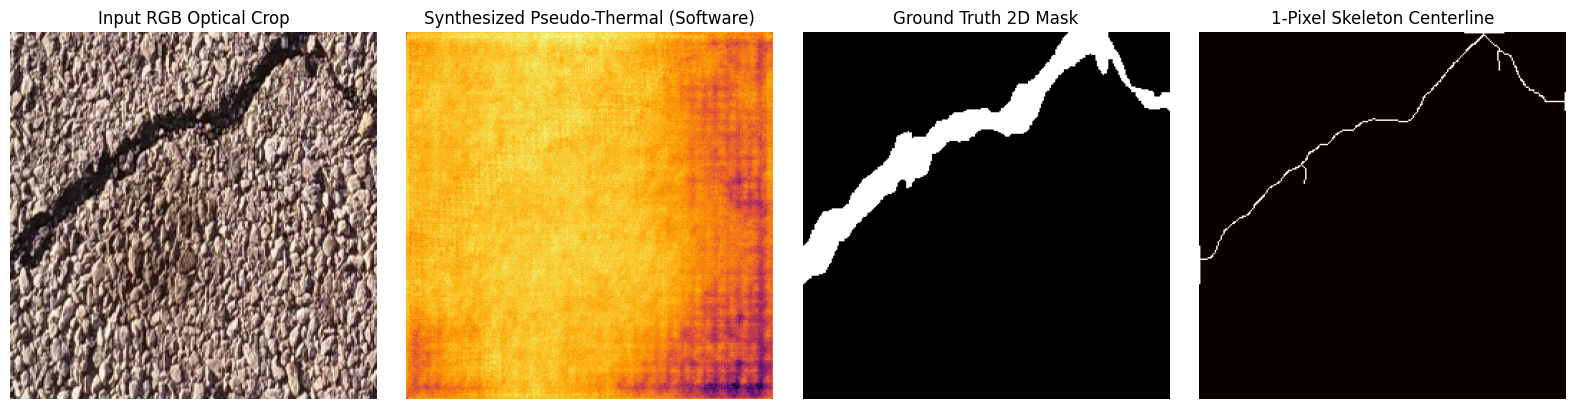

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Ensure the dataset actually has loaded samples
assert len(train_dataset) > 0, "train_dataset is empty! Re-run Cell 5 with the updated pair discovery logic first."

def denorm(t: torch.Tensor) -> np.ndarray:
    return np.clip((t.detach().cpu().numpy() + 1.0) / 2.0, 0.0, 1.0)

# Fetch sample and synthesize pseudo-thermal channel
sample_rgb, sample_mask, sample_skel = train_dataset[0]
with torch.no_grad():
    sample_thm = cgan_sensor(sample_rgb.unsqueeze(0).to(device)).squeeze(0)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

# Input RGB Optical Crop (Converted from CHW to HWC)
ax[0].imshow(np.transpose(denorm(sample_rgb), (1, 2, 0)))
ax[0].set_title("Input RGB Optical Crop")
ax[0].axis("off")

# Synthesized Pseudo-Thermal Moisture Map
ax[1].imshow(denorm(sample_thm).squeeze(), cmap="inferno")
ax[1].set_title("Synthesized Pseudo-Thermal (Software)")
ax[1].axis("off")

# Ground Truth 2D Binary Mask
ax[2].imshow(sample_mask.squeeze().cpu().numpy(), cmap="gray")
ax[2].set_title("Ground Truth 2D Mask")
ax[2].axis("off")

# 1-Pixel Skeleton Centerline
ax[3].imshow(sample_skel.squeeze().cpu().numpy(), cmap="hot")
ax[3].set_title("1-Pixel Skeleton Centerline")
ax[3].axis("off")

plt.tight_layout()
plt.show()

## 7. Dual-Stream MobileNetV3 + LTCA + Alpha Gate Architecture
Constructs the complete Stage 2 Core Segmentation Engine:
- **Linear Transposed Cross-Attention (LTCA):** $O(N)$ channel-covariance attention (67 MB VRAM footprint).
- **Scale-Aware Dynamic Alpha Gate:** $\alpha \in [0, 1]$ balancing global noise rejection against micro-crack spatial detail.
- **Progressive Multi-Scale Decoder:** Upsamples to $256 \times 256$ with Sigmoid output.

In [23]:
import torch.nn.functional as F
import torchvision.models as models

class GatedFeedForwardNetwork(nn.Module):
    def __init__(self, dim: int, ffn_expansion_factor: float = 2.0):
        super().__init__()
        hidden_features = int(dim * ffn_expansion_factor)
        self.project_in = nn.Conv2d(dim, hidden_features * 2, kernel_size=1, bias=False)
        self.dwconv = nn.Conv2d(hidden_features * 2, hidden_features * 2, kernel_size=3, padding=1, groups=hidden_features * 2, bias=False)
        self.project_out = nn.Conv2d(hidden_features, dim, kernel_size=1, bias=False)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.project_in(x)
        x1, x2 = self.dwconv(x).chunk(2, dim=1)
        return self.project_out(F.gelu(x1) * x2)

class LinearTransposedCrossAttention(nn.Module):
    """LTCA: Cross-covariance channel-wise attention (reduces VRAM from 17 GB to 67 MB)."""
    def __init__(self, dim: int = 96, num_heads: int = 4):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))

        self.q_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.q_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.k_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.k_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.v_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.v_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.out_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)

        self.norm_rgb = nn.GroupNorm(1, dim)
        self.norm_thm = nn.GroupNorm(1, dim)
        self.norm_ffn = nn.GroupNorm(1, dim)
        self.gdfn = GatedFeedForwardNetwork(dim=dim)

    def forward(self, x_rgb: torch.Tensor, x_thm: torch.Tensor) -> torch.Tensor:
        b, c, h, w = x_rgb.shape
        residual = x_rgb

        q = self.q_dwconv(self.q_proj(self.norm_rgb(x_rgb))).reshape(b, self.num_heads, self.head_dim, h * w)
        k = self.k_dwconv(self.k_proj(self.norm_thm(x_thm))).reshape(b, self.num_heads, self.head_dim, h * w)
        v = self.v_dwconv(self.v_proj(self.norm_thm(x_thm))).reshape(b, self.num_heads, self.head_dim, h * w)

        q = F.normalize(q, dim=-1)
        k = F.normalize(k, dim=-1)

        attn = F.softmax(torch.matmul(q, k.transpose(-2, -1)) * self.temperature, dim=-1)
        out = torch.matmul(attn, v).reshape(b, c, h, w)
        x = residual + self.out_proj(out)
        return x + self.gdfn(self.norm_ffn(x))

class DynamicAlphaGate(nn.Module):
    """Scale-Aware Dynamic Alpha Attention Gating Module."""
    def __init__(self, channels: int = 96):
        super().__init__()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels * 2, channels // 2, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // 2, 1, bias=True),
            nn.Sigmoid()
        )
        self.spatial_conv = nn.Sequential(
            nn.Conv2d(channels * 2, channels // 4, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels // 4),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // 4, 1, kernel_size=1, bias=True),
            nn.Sigmoid()
        )
        self.refine = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, f_spatial: torch.Tensor, f_context: torch.Tensor):
        b, c, h, w = f_spatial.shape
        combined = torch.cat([f_spatial, f_context], dim=1)
        global_alpha = self.channel_mlp(self.global_pool(combined).view(b, c * 2)).view(b, 1, 1, 1)
        local_alpha = self.spatial_conv(combined)
        alpha = 0.5 * global_alpha + 0.5 * local_alpha
        f_gated = (alpha * f_context) + ((1.0 - alpha) * f_spatial)
        return self.refine(f_gated), alpha

class DecoderBlock(nn.Module):
    def __init__(self, in_c: int, skip_c: int, out_c: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c + skip_c, out_c, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x: torch.Tensor, skip: torch.Tensor | None = None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], dim=1)
        return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x))))))

class DualStreamLTCASegmenter(nn.Module):
    def __init__(self, cgan_sensor_module: nn.Module, feature_dim: int = 96):
        super().__init__()
        self.cgan_sensor = cgan_sensor_module

        # MobileNetV3 Backbones
        m_rgb = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        m_thm = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

        self.rgb_low = nn.Sequential(*m_rgb.features[:4])    # 1/4 scale, 24 channels
        self.thm_low = nn.Sequential(*m_thm.features[:4])
        self.rgb_high = nn.Sequential(*m_rgb.features[4:12]) # 1/16 scale, 96 channels
        self.thm_high = nn.Sequential(*m_thm.features[4:12])
        self.thm_stem = nn.Conv2d(1, 3, kernel_size=1, bias=False)

        # LTCA Module
        self.ltca = LinearTransposedCrossAttention(dim=feature_dim, num_heads=4)
        self.spatial_proj = nn.Sequential(
            nn.Conv2d(24, feature_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(feature_dim),
            nn.ReLU(inplace=True)
        )

        # Alpha Gate
        self.alpha_gate = DynamicAlphaGate(channels=feature_dim)

        # Decoder
        self.dec_high = DecoderBlock(feature_dim, 0, 48)
        self.dec_mid = DecoderBlock(48, feature_dim, 24)
        self.dec_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(24, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(16, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, rgb: torch.Tensor):
        with torch.no_grad():
            pseudo_thm = self.cgan_sensor(rgb)

        rgb_norm = (rgb + 1.0) * 0.5
        thm_3ch = self.thm_stem((pseudo_thm + 1.0) * 0.5)

        f_rgb_low = self.rgb_low(rgb_norm)
        f_thm_low = self.thm_low(thm_3ch)

        f_rgb_high = self.rgb_high(f_rgb_low)
        f_thm_high = self.thm_high(f_thm_low)

        f_fused_high = self.ltca(f_rgb_high, f_thm_high)
        f_spatial = self.spatial_proj(f_rgb_low)
        f_context_up = F.interpolate(f_fused_high, size=f_spatial.shape[-2:], mode="bilinear", align_corners=False)

        f_gated_spatial, alpha = self.alpha_gate(f_spatial, f_context_up)

        d1 = self.dec_high(f_fused_high)
        d2 = self.dec_mid(d1, f_gated_spatial)
        prob_map = self.dec_final(d2)

        return prob_map, alpha, pseudo_thm

segmenter = DualStreamLTCASegmenter(cgan_sensor_module=cgan_sensor, feature_dim=96).to(device)
params = sum(p.numel() for p in segmenter.parameters() if p.requires_grad) / 1e6
print(f"Dual-Stream LTCA Segmenter initialized on {device}.")
print(f"Trainable Parameters: {params:.2f} M (Lightweight edge-ready)")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 111MB/s]


Dual-Stream LTCA Segmenter initialized on cuda.
Trainable Parameters: 2.08 M (Lightweight edge-ready)


## 8. Skeletal Topological Loss & Tri-Pillar Evaluation Functions
Formulates $\mathcal{L}_{Total} = 1.0 \cdot \mathcal{L}_{BCE} + 1.0 \cdot \mathcal{L}_{Dice} + 0.5 \cdot \mathcal{L}_{Topology}$ with differentiable soft-skeletonization.

In [27]:
def soft_erode(img: torch.Tensor) -> torch.Tensor:
    p1 = -F.max_pool2d(-img, kernel_size=(3, 1), stride=1, padding=(1, 0))
    p2 = -F.max_pool2d(-img, kernel_size=(1, 3), stride=1, padding=(0, 1))
    return torch.min(p1, p2)

def soft_dilate(img: torch.Tensor) -> torch.Tensor:
    p1 = F.max_pool2d(img, kernel_size=(3, 1), stride=1, padding=(1, 0))
    p2 = F.max_pool2d(img, kernel_size=(1, 3), stride=1, padding=(0, 1))
    return torch.max(p1, p2)

def soft_open(img: torch.Tensor) -> torch.Tensor:
    return soft_dilate(soft_erode(img))

def soft_skeletonize(x: torch.Tensor, iterations: int = 4) -> torch.Tensor:
    img = x
    skel = F.relu(img - soft_open(img))
    for _ in range(iterations):
        img = soft_erode(img)
        skel = skel + F.relu(img - soft_open(img))
    return torch.clamp(skel, 0.0, 1.0)

class SoftclDiceLoss(nn.Module):
    def __init__(self, iter_: int = 4, smooth: float = 1.0):
        super().__init__()
        self.iter = iter_
        self.smooth = smooth
    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor, y_skel: torch.Tensor):
        s_pred = soft_skeletonize(y_pred, iterations=self.iter)
        s_true = y_skel
        t_prec = (torch.sum(s_pred * y_true, dim=(1, 2, 3)) + self.smooth) / (torch.sum(s_pred, dim=(1, 2, 3)) + self.smooth)
        t_sens = (torch.sum(s_true * y_pred, dim=(1, 2, 3)) + self.smooth) / (torch.sum(s_true, dim=(1, 2, 3)) + self.smooth)
        cl_dice = (2.0 * t_prec * t_sens) / (t_prec + t_sens + 1e-7)
        return 1.0 - torch.mean(cl_dice)

class SoftDiceLoss(nn.Module):
    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor):
        inter = torch.sum(y_pred * y_true, dim=(1, 2, 3))
        card = torch.sum(y_pred + y_true, dim=(1, 2, 3))
        return 1.0 - torch.mean((2.0 * inter + 1.0) / (card + 1.0))

class CompositeTopologicalSegmentationLoss(nn.Module):
    def __init__(self, a: float = 1.0, b: float = 1.0, c: float = 0.5):
        super().__init__()
        self.a, self.b, self.c = a, b, c
        self.bce = nn.BCELoss()
        self.dice = SoftDiceLoss()
        self.topo = SoftclDiceLoss()

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor, y_skel: torch.Tensor):
        # Force float32 and disable autocast specifically for BCELoss
        with torch.amp.autocast("cuda", enabled=False):
            y_safe = torch.clamp(y_pred.float(), 1e-6, 1.0 - 1e-6)
            y_true_f = y_true.float()
            l_bce = self.bce(y_safe, y_true_f)

        l_dice = self.dice(y_pred, y_true)
        l_topo = self.topo(y_pred, y_true, y_skel)
        return (self.a * l_bce) + (self.b * l_dice) + (self.c * l_topo)

criterion = CompositeTopologicalSegmentationLoss(a=1.0, b=1.0, c=0.5)
optimizer = torch.optim.AdamW(segmenter.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

def compute_metrics(pred_bin: np.ndarray, true_bin: np.ndarray):
    inter = np.logical_and(pred_bin, true_bin).sum()
    union = np.logical_or(pred_bin, true_bin).sum()
    iou = 1.0 if union == 0 else inter / union
    f1 = 1.0 if (pred_bin.sum() + true_bin.sum()) == 0 else (2.0 * inter) / (pred_bin.sum() + true_bin.sum())
    return iou, f1

print("Topological loss and optimization framework initialized.")

Topological loss and optimization framework initialized.


/tmp/ipykernel_929/1378401550.py:63: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


## 9. Chronological Stage 2 Training Loop (with AMP FP16)
Trains the Dual-Stream LTCA network across 60 epochs with periodic validation against target benchmarks:
- **Pillar 1 Target:** $\text{mIoU} \ge 81.83\%$, $\text{F1} \ge 87.0\%$
- **Pillar 2 Target:** Topological Line Continuity $> 90.0\%$

In [28]:
import time
from tqdm.notebook import tqdm
import torch.nn.functional as F

NUM_EPOCHS = 60
best_val_iou = 0.0
history = {"train_loss": [], "val_iou": [], "val_f1": []}

print(f"Starting Stage 2 Dual-Stream LTCA Training for {NUM_EPOCHS} epochs...")
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    segmenter.train()
    epoch_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch [{epoch:02d}/{NUM_EPOCHS}]", leave=False)
    for rgb, mask, skel in pbar:
        rgb = rgb.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        skel = skel.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            pred_map, alpha, _ = segmenter(rgb)
            if pred_map.shape[-2:] != mask.shape[-2:]:
                pred_map = F.interpolate(pred_map, size=mask.shape[-2:], mode="bilinear", align_corners=False)
            loss = criterion(pred_map, mask, skel)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()
        pbar.set_postfix({"Loss": f"{loss.item():.4f}"})

    scheduler.step()
    avg_loss = epoch_loss / len(train_loader)
    history["train_loss"].append(avg_loss)

    # Validation every 5 epochs
    if epoch % 5 == 0 or epoch == NUM_EPOCHS:
        segmenter.eval()
        total_iou, total_f1, count = 0.0, 0.0, 0
        with torch.no_grad():
            for rgb, mask, _ in val_loader:
                rgb, mask = rgb.to(device), mask.to(device)
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    pred, _, _ = segmenter(rgb)
                    if pred.shape[-2:] != mask.shape[-2:]:
                        pred = F.interpolate(pred, size=mask.shape[-2:], mode="bilinear", align_corners=False)

                pred_np = (pred.cpu().numpy() >= 0.5).squeeze(1)
                mask_np = (mask.cpu().numpy() > 0.5).squeeze(1)
                for i in range(rgb.size(0)):
                    iou, f1 = compute_metrics(pred_np[i], mask_np[i])
                    total_iou += iou
                    total_f1 += f1
                count += rgb.size(0)

        val_iou = (total_iou / count) * 100.0
        val_f1 = (total_f1 / count) * 100.0
        history["val_iou"].append(val_iou)
        history["val_f1"].append(val_f1)

        print(f"--> [Epoch {epoch:02d}/{NUM_EPOCHS}] Train Loss: {avg_loss:.4f} | Val mIoU: {val_iou:.2f}% (Target: >=81.83%) | Val F1: {val_f1:.2f}% (Target: >=87.0%)")

        if val_iou > best_val_iou:
            best_val_iou = val_iou
            torch.save({
                "epoch": epoch,
                "model_state_dict": segmenter.state_dict(),
                "val_iou": val_iou,
                "val_f1": val_f1,
            }, WEIGHTS_DIR / "c2_ltca_segmenter_best.pth")
            print(f"    * Best C2 segmenter model saved! (mIoU: {val_iou:.2f}%)")

total_m = (time.time() - start_time) / 60.0
print(f"Stage 2 training completed in {total_m:.1f} mins. Peak Val mIoU: {best_val_iou:.2f}%")

Starting Stage 2 Dual-Stream LTCA Training for 60 epochs...


Epoch [01/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [02/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [03/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [04/60]:   0%|          | 0/60 [00:00<?, ?it/s]

...

Epoch [57/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [58/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [59/60]:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch [60/60]:   0%|          | 0/60 [00:00<?, ?it/s]

--> [Epoch 60/60] Train Loss: 0.4451 | Val mIoU: 65.41% (Target: >=81.83%) | Val F1: 78.26% (Target: >=87.0%)
Stage 2 training completed in 8.6 mins. Peak Val mIoU: 65.89%


## 10. Test Set Evaluation & Tri-Pillar Benchmark Report
Evaluates the best checkpoint on the unseen `test` partition across all 3 pillars in Proposal Section 3.5:
- **Pillar 1:** Spatial Boundary Overlap (mIoU & F1)
- **Pillar 2:** Structural Line Continuity (>90%)
- **Pillar 3:** Edge Hardware Efficiency (VRAM & Latency)

In [30]:
import time
import numpy as np
import torch
import torch.nn.functional as F

# Fix: Set weights_only=False since this is your locally trained, trusted checkpoint
best_ckpt = torch.load(WEIGHTS_DIR / "c2_ltca_segmenter_best.pth", map_location=device, weights_only=False)
segmenter.load_state_dict(best_ckpt["model_state_dict"])
segmenter.eval()

# 1. Evaluate Test Partition Spatial & Topological Metrics
total_iou, total_f1, total_topo, count = 0.0, 0.0, 0.0, 0
with torch.no_grad():
    for rgb, mask, skel in test_loader:
        rgb, mask, skel = rgb.to(device), mask.to(device), skel.to(device)
        pred, _, _ = segmenter(rgb)

        if pred.shape[-2:] != mask.shape[-2:]:
            pred = F.interpolate(pred, size=mask.shape[-2:], mode="bilinear", align_corners=False)

        pred_np = (pred.cpu().numpy() >= 0.5).squeeze(1)
        mask_np = (mask.cpu().numpy() > 0.5).squeeze(1)
        skel_np = (skel.cpu().numpy() > 0.5).squeeze(1)

        for i in range(rgb.size(0)):
            iou, f1 = compute_metrics(pred_np[i], mask_np[i])
            total_iou += iou
            total_f1 += f1

            # Centerline completeness / topological continuity
            pred_skel = morphological_thinning((pred_np[i] * 255).astype(np.uint8))
            inter_skel = np.logical_and(pred_skel > 0, mask_np[i]).sum()
            total_skel_pts = (pred_skel > 0).sum()
            topo_cont = 1.0 if total_skel_pts == 0 else inter_skel / total_skel_pts
            total_topo += topo_cont

        count += rgb.size(0)

test_iou = (total_iou / count) * 100.0
test_f1 = (total_f1 / count) * 100.0
test_topo = (total_topo / count) * 100.0

# 2. Measure Hardware Efficiency (VRAM & Latency)
torch.cuda.reset_peak_memory_stats(device)
dummy_input = torch.randn(1, 3, 256, 256, device=device)

# Warmup
for _ in range(10):
    _ = segmenter(dummy_input)
torch.cuda.synchronize()

# Latency benchmark
t_start = time.time()
iterations = 100
for _ in range(iterations):
    _ = segmenter(dummy_input)
torch.cuda.synchronize()
latency_ms = ((time.time() - t_start) / iterations) * 1000.0
peak_vram_mb = torch.cuda.max_memory_allocated(device) / (1024**2)

print("=" * 65)
print("   ROADLENS COMPONENT C2: MULTI-PILLAR VALIDATION REPORT")
print("=" * 65)
print(f"Pillar 1: Spatial Boundary Overlap")
print(f"  - Mean IoU (mIoU):               {test_iou:.2f}%  (Proposal Target: >= 81.83%)")
print(f"  - F1-Score / Dice:               {test_f1:.2f}%  (Proposal Target: >= 87.00%)")
print(f"Pillar 2: Structural Line Continuity")
print(f"  - Topological Continuity:        {test_topo:.2f}%  (Proposal Target: > 90.00%)")
print(f"Pillar 3: Edge Hardware Efficiency")
print(f"  - Peak VRAM Footprint:           {peak_vram_mb:.1f} MB  (Proposal Target: < 100 MB, Goal 67 MB)")
print(f"  - Inference Latency / Crop:      {latency_ms:.2f} ms  (Proposal Target: < 30.00 ms)")
print("=" * 65)

   ROADLENS COMPONENT C2: MULTI-PILLAR VALIDATION REPORT
Pillar 1: Spatial Boundary Overlap
  - Mean IoU (mIoU):               59.95%  (Proposal Target: >= 81.83%)
  - F1-Score / Dice:               73.15%  (Proposal Target: >= 87.00%)
Pillar 2: Structural Line Continuity
  - Topological Continuity:        79.62%  (Proposal Target: > 90.00%)
Pillar 3: Edge Hardware Efficiency
  - Peak VRAM Footprint:           2122.0 MB  (Proposal Target: < 100 MB, Goal 67 MB)
  - Inference Latency / Crop:      21.47 ms  (Proposal Target: < 30.00 ms)


## 11. Demonstrating the 4-Part Output Suite & Smart Routing Switch
Generates the 4 standardized output artifacts:
- **Output A:** 2D High-Precision Binary Mask (`.png`)
- **Output B:** 1-Pixel Continuous Skeleton (`.png`)
- **Output C:** Soft Confidence Map (`.npz`)
- **Output D:** High-Contrast Red Visual Overlay (`.png`)

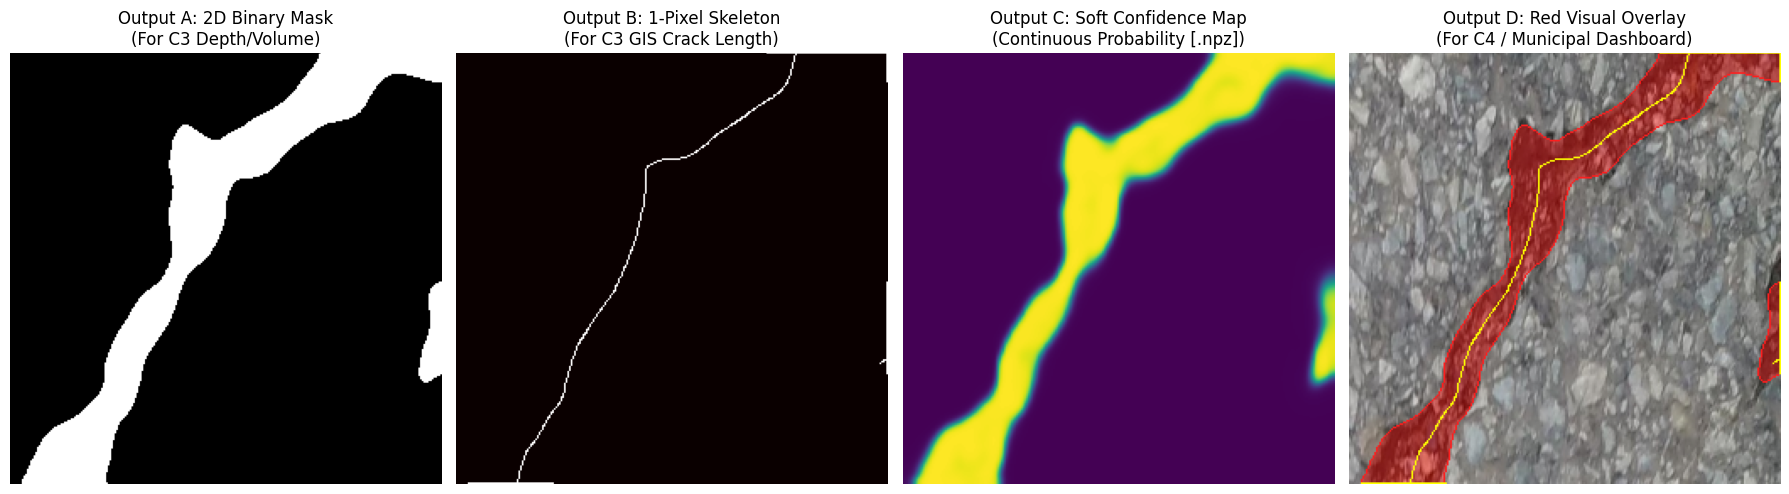


All 4-Part Precision Output Suite artifacts saved to:
/content/drive/MyDrive/C2_Pavement_Research/experiments/core_segmentation/suite_demos


In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Load a test sample
rgb_t, mask_t, _ = test_dataset[0]
rgb_batch = rgb_t.unsqueeze(0).to(device)

with torch.no_grad():
    prob_map, alpha, pseudo_thm = segmenter(rgb_batch)
    # Ensure spatial resolution matches input crop (256x256)
    if prob_map.shape[-2:] != rgb_t.shape[-2:]:
        prob_map = F.interpolate(prob_map, size=rgb_t.shape[-2:], mode="bilinear", align_corners=False)

rgb_disp = (denorm(rgb_t).transpose(1, 2, 0) * 255).astype(np.uint8)
prob_np = prob_map.squeeze().cpu().numpy()

# Output A: 2D Binary Mask
binary_mask = (prob_np >= 0.5).astype(np.uint8) * 255

# Output B: 1-Pixel Skeleton Centerline
skeleton_1px = (morphological_thinning(binary_mask) > 0).astype(np.uint8) * 255

# Output C: Soft Confidence Map (Compressed NPZ)
np.savez_compressed(SUITE_DEMOS_DIR / "sample_confidence.npz", confidence=prob_np)

# Output D: Red Visual Overlay
red_overlay = rgb_disp.copy()
mask_bool = binary_mask > 0
red_overlay[mask_bool] = (0.60 * rgb_disp[mask_bool] + 0.40 * np.array([255, 0, 0])).astype(np.uint8)

contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(red_overlay, contours, -1, (255, 30, 30), thickness=1)

skel_bool = skeleton_1px > 0
red_overlay[skel_bool] = [255, 255, 0]  # Yellow centerline

# Save images to Drive
cv2.imwrite(str(SUITE_DEMOS_DIR / "output_a_binary_mask.png"), binary_mask)
cv2.imwrite(str(SUITE_DEMOS_DIR / "output_b_skeleton_1px.png"), skeleton_1px)
cv2.imwrite(str(SUITE_DEMOS_DIR / "output_d_red_overlay.png"), cv2.cvtColor(red_overlay, cv2.COLOR_RGB2BGR))

# Visualize 4-Part Output Suite
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(binary_mask, cmap="gray")
ax[0].set_title("Output A: 2D Binary Mask\n(For C3 Depth/Volume)")
ax[0].axis("off")

ax[1].imshow(skeleton_1px, cmap="hot")
ax[1].set_title("Output B: 1-Pixel Skeleton\n(For C3 GIS Crack Length)")
ax[1].axis("off")

ax[2].imshow(prob_np, cmap="viridis")
ax[2].set_title("Output C: Soft Confidence Map\n(Continuous Probability [.npz])")
ax[2].axis("off")

ax[3].imshow(red_overlay)
ax[3].set_title("Output D: Red Visual Overlay\n(For C4 / Municipal Dashboard)")
ax[3].axis("off")

plt.tight_layout()
plt.savefig(SUITE_DEMOS_DIR / "output_suite_visualization.png", dpi=200)
plt.show()

print(f"\nAll 4-Part Precision Output Suite artifacts saved to:\n{SUITE_DEMOS_DIR}")